In [1]:
import kagglehub
path = kagglehub.dataset_download("chetankv/dogs-cats-images")

print("Path to dataset files:", path)

100%|██████████| 435M/435M [00:02<00:00, 162MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/chetankv/dogs-cats-images/versions/1


In [2]:
import os
os.listdir(path)

['dog vs cat', 'dataset']

In [3]:
dataset_path = os.path.join(path, "dataset")
os.listdir(dataset_path)

['test_set', 'training_set']

In [4]:
train_path = os.path.join(dataset_path, "training_set")
test_path = os.path.join(dataset_path, "test_set")
print(os.listdir(train_path))

['cats', 'dogs']


In [5]:
test_path = os.path.join(dataset_path, "test_set")
print(os.listdir(test_path))

['cats', 'dogs']


In [6]:
cats_train = os.path.join(train_path,"cats")
dogs_train = os.path.join(train_path,"dogs")

cats_test = os.path.join(test_path,"cats")
dogs_test = os.path.join(test_path,"dogs")



In [7]:
print(len(os.listdir(cats_train)))
print(len(os.listdir(dogs_train)))

4000
4000


(np.float64(-0.5), np.float64(331.5), np.float64(318.5), np.float64(-0.5))

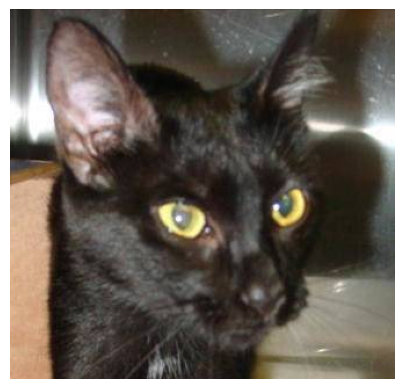

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img_path = os.path.join(cats_train, os.listdir(cats_train)[0])
img = mpimg.imread(img_path)

plt.imshow(img)
plt.axis('off')

In [9]:
print(img.shape)

(319, 332, 3)


In [10]:
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [11]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
test_datagen = ImageDataGenerator(rescale=1./255)

training_set = train_datagen.flow_from_directory(
    train_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='binary'
)

test_set = test_datagen.flow_from_directory(
    test_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='binary'
)

Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
model = Sequential()

In [13]:
model.add(Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=(128,128,3)))
model.add(MaxPooling2D(pool_size=2))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.add(Conv2D(filters=32, kernel_size=3, activation='relu'))
model.add(MaxPooling2D(pool_size=2))

In [15]:
model.add(Flatten())
model.add(Dense(units=128, activation='relu'))
model.add(Dense(units=1, activation='sigmoid'))

In [16]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(
    training_set,
    epochs=10,
    validation_data=test_set
)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 51s 185ms/step - accuracy: 0.5801 - loss: 0.6825 - val_accuracy: 0.5600 - val_loss: 0.6949
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 43s 171ms/step - accuracy: 0.6800 - loss: 0.5942 - val_accuracy: 0.7115 - val_loss: 0.5726
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 43s 170ms/step - accuracy: 0.7278 - loss: 0.5362 - val_accuracy: 0.7245 - val_loss: 0.5450
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 168ms/step - accuracy: 0.7516 - loss: 0.5101 - val_accuracy: 0.7480 - val_loss: 0.4975
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 43s 171ms/step - accuracy: 0.7714 - loss: 0.4776 - val_accuracy: 0.7820 - val_loss: 0.4860
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 170ms/step - accuracy: 0.7821 - loss: 0.4602 - val_accuracy: 0.7895 - val_loss: 0.4661
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 45s 180ms/step - accuracy: 0.7870 - loss: 0.4462 - val_accuracy: 0.8015 - val_loss: 0.4478
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 42s 170ms/step - accuracy: 0.8044 - loss: 0

In [17]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

NameError: name 'history' is not defined

In [19]:
import numpy as np
from tensorflow.keras.preprocessing import image
import os
dog_image_path = os.path.join(dogs_test, os.listdir(dogs_test)[0])
img = image.load_img(dog_image_path, target_size=(128,128))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = img_array/255.0

prediction = model.predict(img_array)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 541ms/step
[[0.96271694]]


In [22]:
from google.colab import files
uploaded = files.upload()

Saving images.jpg to images.jpg


In [23]:
if prediction[0][0] > 0.5:
    print("Dog")
else:
    print("Cat")

Dog
